
Future three-cycle mean SoH: unseen chronological test metrics
                         MAE    RMSE      R2
Random Forest         0.3706  0.5421  0.7333
Persistence baseline  0.7471  0.7896  0.4342


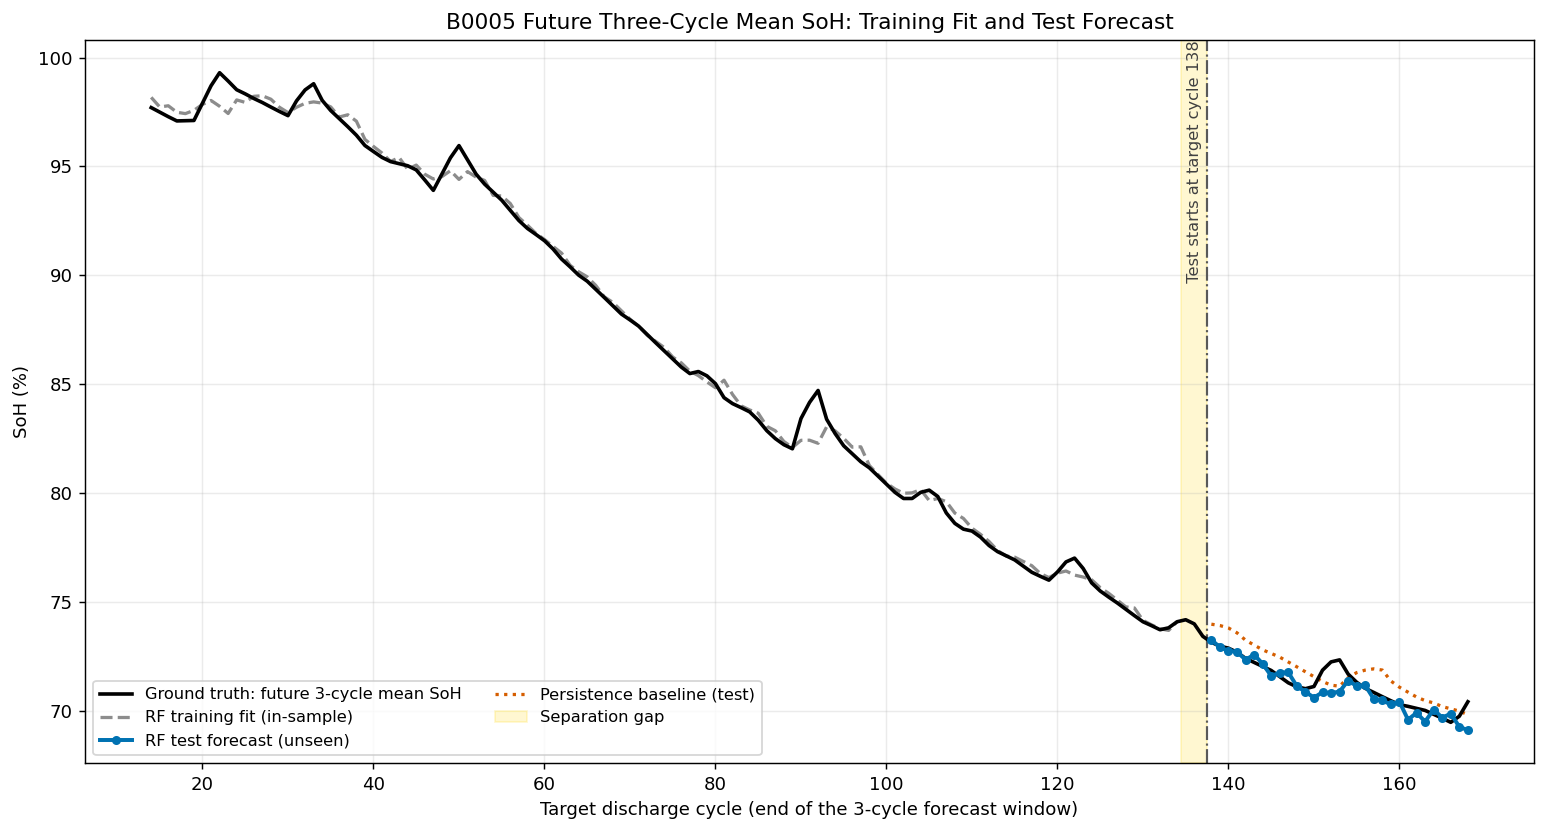

In [8]:
"""Simplified Random Forest forecast of B0005 future three-cycle mean SoH.

Place this script and nasa_B0005_top3_features_SOH.csv in the same folder.
"""

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# 1. Load the 168-cycle summarised B0005 dataset
folder = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
csv_path = folder / "nasa_B0005_top3_features_SOH.csv"

if not csv_path.exists():
    raise FileNotFoundError(
        f"CSV file not found: {csv_path}\n"
        "Place nasa_B0005_top3_features_SOH.csv in the same folder as this code."
    )

data = pd.read_csv(csv_path).sort_values("discharge_cycle").reset_index(drop=True)

required_columns = {
    "discharge_cycle",
    "voltage_mean_V",
    "current_mean_A",
    "SOH_pct",
}
if not required_columns.issubset(data.columns):
    raise ValueError(f"Required columns are: {sorted(required_columns)}")


# 2. Create a causal SoH trend and historical features
# The trailing average uses only the current and four previous cycles.
data["SOH_trend"] = data["SOH_pct"].rolling(window=5, min_periods=1).mean()

signals = ["SOH_trend", "voltage_mean_V", "current_mean_A"]
lags = [1, 3, 5, 10]

for signal in signals:
    for lag in lags:
        data[f"{signal}_change_{lag}"] = data[signal] - data[signal].shift(lag)

# Leakage-free target: average SoH across the next three cycles only.
# At input cycle t, the target contains t+1, t+2 and t+3; it contains no
# current or historical SoH values.
data["future_SOH_3cycle_mean"] = (
    data["SOH_pct"].shift(-1)
    + data["SOH_pct"].shift(-2)
    + data["SOH_pct"].shift(-3)
) / 3
data["Delta_SoH_3"] = data["future_SOH_3cycle_mean"] - data["SOH_trend"]

features = [
    "discharge_cycle",
    "voltage_mean_V",
    "current_mean_A",
    "SOH_trend",
] + [f"{signal}_change_{lag}" for signal in signals for lag in lags]

model_data = data.dropna(
    subset=features + ["future_SOH_3cycle_mean", "Delta_SoH_3"]
).copy()


# 3. Chronological development/gap/test split
# Development inputs 11-131 predict target cycles 14-134.
# Input cycles 132-134 form the three-cycle separation gap.
# Test inputs 135-165 predict target cycles 138-168.
development = model_data[model_data["discharge_cycle"] <= 131]
test = model_data[model_data["discharge_cycle"] >= 135].copy()


# 4. Train the Random Forest
model = RandomForestRegressor(
    n_estimators=500,
    min_samples_leaf=4,
    max_features=0.7,
    random_state=42,
    n_jobs=-1,
)

model.fit(development[features], development["Delta_SoH_3"])

development = development.copy()
development["predicted_SOH"] = development["SOH_trend"] + model.predict(
    development[features]
)
development["target_cycle"] = development["discharge_cycle"] + 3

test["predicted_SOH"] = test["SOH_trend"] + model.predict(test[features])
test["baseline_SOH"] = test["SOH_trend"]
test["target_cycle"] = test["discharge_cycle"] + 3

# The target is a mean of cycles t+1 to t+3 and is positioned at the final
# cycle in that forecast window. This gives target cycles 14-168.
model_data["target_cycle"] = model_data["discharge_cycle"] + 3


# 5. Print evaluation metrics
def metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": mean_squared_error(actual, predicted) ** 0.5,
        "R2": r2_score(actual, predicted),
    }


results = pd.DataFrame(
    {
        "Random Forest": metrics(
            test["future_SOH_3cycle_mean"], test["predicted_SOH"]
        ),
        "Persistence baseline": metrics(
            test["future_SOH_3cycle_mean"], test["baseline_SOH"]
        ),
    }
).T

print("\nFuture three-cycle mean SoH: unseen chronological test metrics")
print(results.round(4))


# 6. Display the complete lifecycle plot (nothing is exported)
figure, axis = plt.subplots(figsize=(12, 6.5))

axis.plot(
    model_data["target_cycle"],
    model_data["future_SOH_3cycle_mean"],
    color="black",
    linewidth=2.0,
    label="Ground truth: future 3-cycle mean SoH",
    zorder=4,
)
axis.plot(
    development["target_cycle"],
    development["predicted_SOH"],
    color="0.55",
    linestyle="--",
    linewidth=1.8,
    label="RF training fit (in-sample)",
    zorder=2,
)
axis.plot(
    test["target_cycle"],
    test["predicted_SOH"],
    color="#0072B2",
    marker="o",
    markersize=4,
    linewidth=2.2,
    label="RF test forecast (unseen)",
    zorder=5,
)
axis.plot(
    test["target_cycle"],
    test["baseline_SOH"],
    color="#D55E00",
    linestyle=":",
    linewidth=1.8,
    label="Persistence baseline (test)",
    zorder=3,
)

# Inputs 132-134 are deliberately excluded. On the target-cycle axis they
# correspond to forecast endpoints 135-137.
axis.axvspan(134.5, 137.5, color="gold", alpha=0.18, label="Separation gap")
axis.axvline(137.5, color="0.35", linestyle="-.", linewidth=1.2)
axis.text(
    136,
    axis.get_ylim()[1],
    "  Test starts at target cycle 138",
    rotation=90,
    va="top",
    ha="center",
    fontsize=9,
    color="0.25",
)

axis.set_title("B0005 Future Three-Cycle Mean SoH: Training Fit and Test Forecast")
axis.set_xlabel("Target discharge cycle (end of the 3-cycle forecast window)")
axis.set_ylabel("SoH (%)")
axis.grid(alpha=0.25)
axis.legend(ncol=2, fontsize=9)
figure.tight_layout()

# Jupyter can render a figure even when its backend is non-interactive (Agg).
# A normal Python/VS Code terminal instead opens a blocking plot window.
try:
    notebook_shell = get_ipython()  # type: ignore[name-defined]
except NameError:
    notebook_shell = None

if notebook_shell is not None:
    # Render to memory so the image appears even when the notebook inherited
    # Matplotlib's non-interactive Agg backend. No file is written.
    from io import BytesIO
    from IPython.display import Image, display

    image_buffer = BytesIO()
    figure.savefig(image_buffer, format="png", dpi=130, bbox_inches="tight")
    display(Image(data=image_buffer.getvalue()))
    image_buffer.close()
    plt.close(figure)
else:
    plt.show(block=True)
